In [1]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

In [2]:
# Load noisy observations
df = pd.read_csv('Dataset.csv')
t_data = torch.tensor(df['t'].values, dtype=torch.float32).unsqueeze(1)
x_data = torch.tensor(df['x'].values, dtype=torch.float32).unsqueeze(1)
# Generate dense time points (collocation points) for computing physics loss
t_colloc = torch.linspace(t_data.min(), t_data.max(), 200, dtype=torch.float32).unsqueeze(1)
t_colloc.requires_grad = True  # Required for autograd derivatives

In [3]:
class SpringDamperPINN(nn.Module):
    def __init__(self, hidden_dim=64):
        super().__init__()
        # Deep Neural Network predicting trajectory x(t) from input time t
        self.net = nn.Sequential(
            nn.Linear(1, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, 1)
        )
        # Using softplus or raw nn.Parameter ensures gradient updates work smoothly
        self.c_raw = nn.Parameter(torch.tensor(1.0))
        self.k_raw = nn.Parameter(torch.tensor(1.0))
    @property
    def c(self):
        return torch.nn.functional.softplus(self.c_raw)  # Guarantees c &gt; 0
    @property
    def k(self):
        return torch.nn.functional.softplus(self.k_raw)  # Guarantees k &gt; 0
    def forward(self, t):
        return self.net(t)

In [12]:
def compute_physics_loss(model, t_colloc, m=1.0):
    # Predict x(t)
    x_pred = model(t_colloc)
    # 1st Derivative: dx/dt
    dx_dt = torch.autograd.grad(
        outputs=x_pred, inputs=t_colloc,
        grad_outputs=torch.ones_like(x_pred),
        create_graph=True, retain_graph=True
    )[0]
    # 2nd Derivative: d2x/dt2
    d2x_dt2 = torch.autograd.grad(
        outputs=dx_dt, inputs=t_colloc,
        grad_outputs=torch.ones_like(dx_dt),
        create_graph=True, retain_graph=True
    )[0]
    # ODE Residual: m*x'' + c*x' + k*x = 0
    residual = m * d2x_dt2 + model.c * dx_dt + model.k * x_pred
    return torch.mean(residual ** 2)

In [13]:
pinn = SpringDamperPINN(hidden_dim=64)
optimizer = torch.optim.Adam(pinn.parameters(), lr=1e-3)
epochs = 10000
c_history, k_history, loss_history = [], [], []

for epoch in range(1, epochs + 1):
    optimizer.zero_grad()
    # Data Loss (fit to sparse noisy data)
    x_pred_data = pinn(t_data)
    loss_data = torch.mean((x_pred_data - x_data) ** 2)
    # Physics Loss (enforce ODE)
    loss_phys = compute_physics_loss(pinn, t_colloc)
    # Total Combined Loss
    total_loss = loss_data + 0.1 * loss_phys
    total_loss.backward()
    optimizer.step()
    # Save parameter traces
    c_history.append(pinn.c.item())
    k_history.append(pinn.k.item())
    loss_history.append(total_loss.item())
    
    if epoch % 1000 == 0 or epoch == 1:
        print(f"Epoch {epoch:5d} | Loss: {total_loss.item():.6f} | c: {pinn.c.item():.4f} | k: {pinn.k.item():.4f}")

Epoch     1 | Loss: 0.115822 | c: 1.3125 | k: 1.3125
Epoch  1000 | Loss: 0.005455 | c: 0.8036 | k: 1.5844
Epoch  2000 | Loss: 0.052980 | c: 0.6428 | k: 1.5596
Epoch  3000 | Loss: 0.001536 | c: 0.5883 | k: 1.4840
Epoch  4000 | Loss: 0.000763 | c: 0.5382 | k: 1.4534
Epoch  5000 | Loss: 0.000420 | c: 0.5350 | k: 1.4488
Epoch  6000 | Loss: 0.000243 | c: 0.5416 | k: 1.4554
Epoch  7000 | Loss: 0.000169 | c: 0.5444 | k: 1.4677
Epoch  8000 | Loss: 0.000137 | c: 0.5458 | k: 1.4721
Epoch  9000 | Loss: 0.000124 | c: 0.5474 | k: 1.4772
Epoch 10000 | Loss: 0.000117 | c: 0.5477 | k: 1.4784


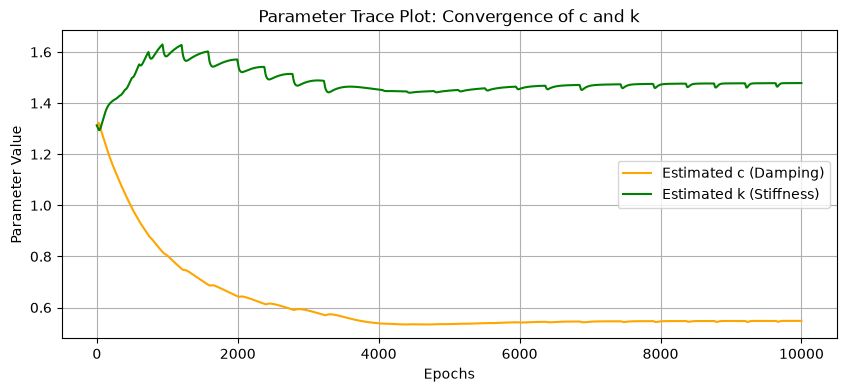

In [14]:
plt.figure(figsize=(10, 4))
plt.plot(c_history, label='Estimated c (Damping)', color='orange')
plt.plot(k_history, label='Estimated k (Stiffness)', color='green')
plt.xlabel('Epochs')
plt.ylabel('Parameter Value')
plt.title('Parameter Trace Plot: Convergence of c and k')
plt.legend()
plt.grid(True)
plt.show()

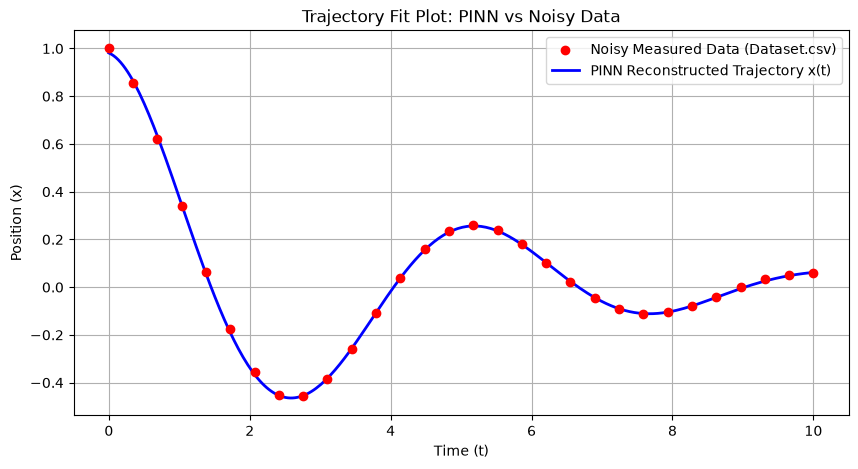

In [17]:
t_dense = torch.linspace(t_data.min(), t_data.max(), 300).unsqueeze(1)

with torch.no_grad():
    x_dense_pred = pinn(t_dense).numpy()

plt.figure(figsize=(10, 5))
plt.scatter(t_data.numpy(), x_data.numpy(), color='red', label='Noisy Measured Data (Dataset.csv)', zorder=3)
plt.plot(t_dense.numpy(), x_dense_pred, color='blue', linewidth=2, label='PINN Reconstructed Trajectory x(t)')
plt.xlabel('Time (t)')
plt.ylabel('Position (x)')
plt.title('Trajectory Fit Plot: PINN vs Noisy Data')
plt.legend()
plt.grid(True)
plt.show()

#### Discovered Physical Parameters

Damping Coefficient (c) = 0.55

Spring Stiffness (k) = 1.48